# 01 · Data exploration
MovieMatch (ES 335). Loads MovieLens 100K, checks it against the README, and runs the data-quality checks and exploratory plots from Section 5 of the project guide.

If the data is missing, run `python -m src.load_data` from the project root first.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
from IPython.display import Image, display
from src import config as C, load_data as L, preprocessing as P, features as F

## Load and verify
`u.item` is pipe-separated and Latin-1 encoded, even though the README says tab-separated.

In [2]:
ratings, movies = L.load_ratings(), L.load_movies()
print(L.verify_counts(ratings, movies))
ratings.head()

{'n_ratings': 100000, 'n_users': 943, 'n_movies_rated': 1682, 'n_movies_in_catalogue': 1682}


,user_id,movie_id,rating,timestamp
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


In [3]:
movies[['movie_id','title','release_date','release_year'] + C.GENRES[:6]].head()

,movie_id,title,release_date,release_year,unknown,Action,Adventure,Animation,Children's,Comedy
0,1,Toy Story (1995),1995-01-01,1995.0,0,0,0,1,1,1
1,2,GoldenEye (1995),1995-01-01,1995.0,0,1,1,0,0,0
2,3,Four Rooms (1995),1995-01-01,1995.0,0,0,0,0,0,0
3,4,Get Shorty (1995),1995-01-01,1995.0,0,1,0,0,0,1
4,5,Copycat (1995),1995-01-01,1995.0,0,0,0,0,0,0


## Data-quality checks

In [4]:
pd.Series(P.quality_report(ratings, movies))

missing_values_ratings             0
missing_release_date               1
duplicate_user_movie_pairs         0
fully_duplicate_rows               0
ratings_outside_1_5                0
unmatched_movie_ids_after_join     0
movies_with_unknown_genre_flag     2
movies_with_no_genre_flag          0
duplicate_titles_in_catalogue     18
dtype: int64

No missing ratings, no duplicate user-movie pairs, all ratings within 1-5, and every movie ID joins. One movie has no release date (imputed later inside the model pipeline). 18 titles appear twice in `u.item` under different IDs; we keep IDs as given and treat them as separate items.

## Target and summary

In [5]:
df = P.add_target(ratings)
summary = {'ratings': len(df), 'users': df.user_id.nunique(), 'movies': df.movie_id.nunique(),
           'first': df.datetime.min(), 'last': df.datetime.max(),
           'positive_rate (4-5 stars)': round(df.target.mean(), 4),
           'sparsity': round(1 - len(df) / (df.user_id.nunique() * len(movies)), 4)}
pd.Series(summary)

ratings                                         100000
users                                              943
movies                                            1682
first                        1997-09-20 03:05:10+00:00
last                         1998-04-22 23:10:38+00:00
positive_rate (4-5 stars)                       0.5538
sparsity                                         0.937
dtype: object

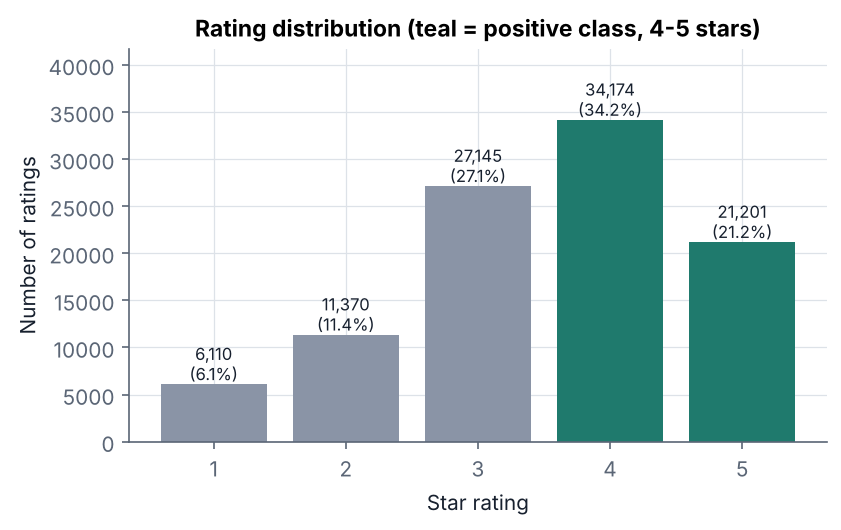

In [6]:
display(Image(str(C.FIG_DIR / 'eda_rating_distribution.png')))

The positive class (4-5 stars) is the majority at about 55%, so a model that always says *positive* already gets ~55% accuracy. This is why accuracy alone is not enough.

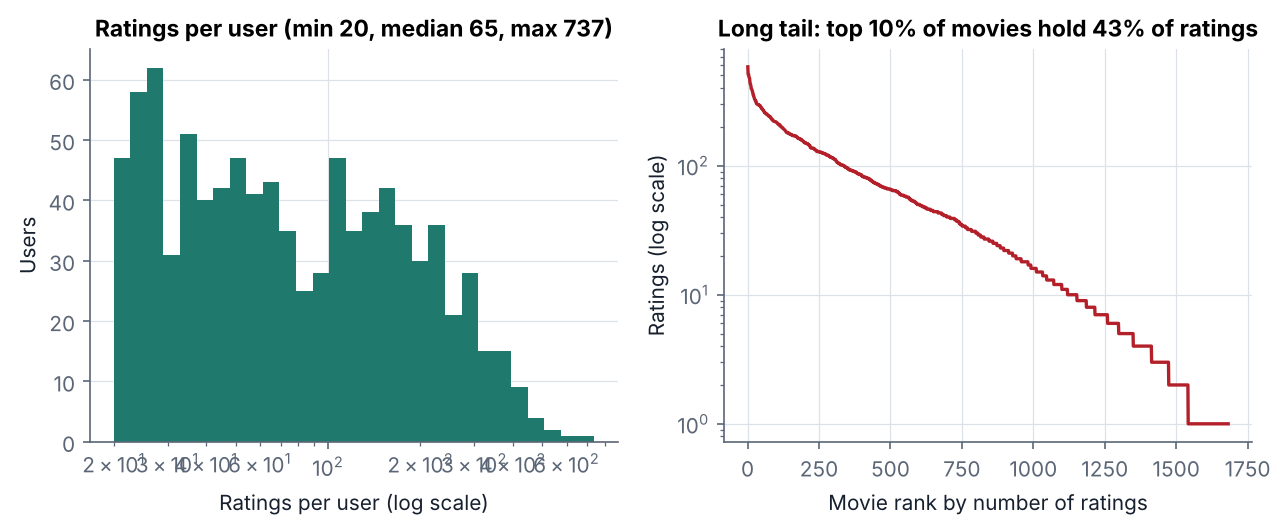

movies with < 5 ratings: 333


In [7]:
display(Image(str(C.FIG_DIR / 'eda_ratings_per_user_movie.png')))
pm = df.groupby('movie_id').size(); print('movies with < 5 ratings:', (pm < 5).sum())

Every user has at least 20 ratings (by construction of the dataset), but movie popularity is a long tail: a small set of movies gets most ratings, so movie statistics are reliable for some movies and very noisy for others. This motivates the smoothed (shrunk) movie averages used as features.

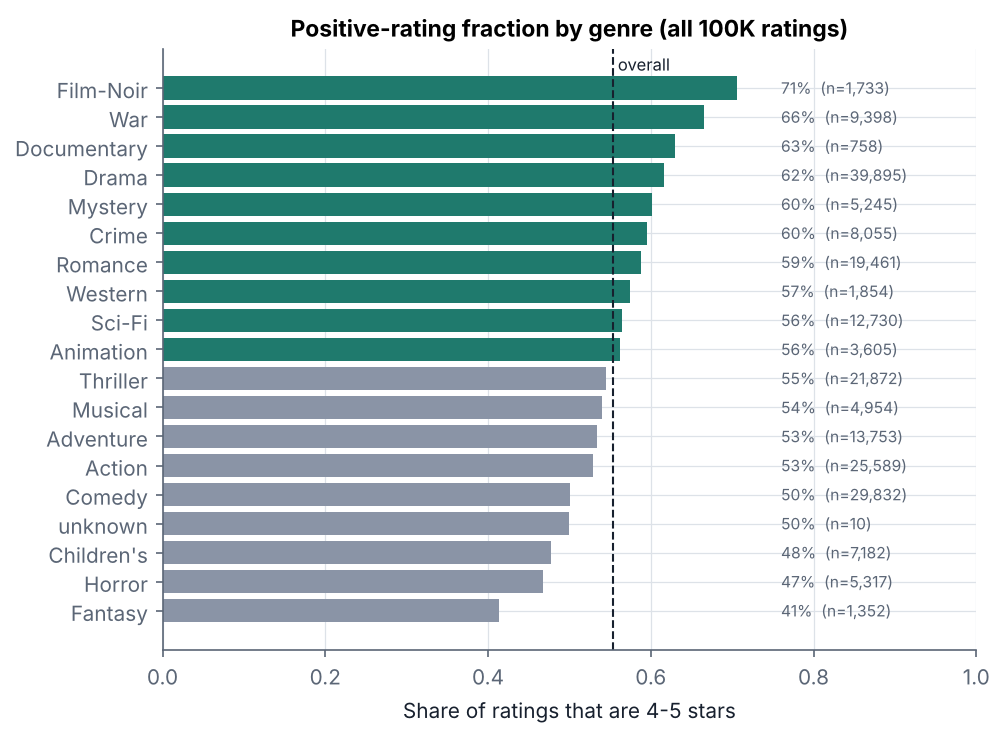

In [8]:
display(Image(str(C.FIG_DIR / 'eda_genre_positive_fraction.png')))

Positive rates differ by genre (Film-Noir and War high; Fantasy, Horror, Children's low). Several genres have few ratings, so the counts are printed next to the fractions.

## Time coverage and the split

In [9]:
split_df, info = P.chronological_split(df)
pd.DataFrame({k: v for k, v in info.items() if isinstance(v, dict)})

,train,val,test
rows,79999,10001,10000
share,0.8,0.1,0.1
first,1997-09-20 03:05:10+00:00,1998-03-07 02:21:09+00:00,1998-03-31 22:11:49+00:00
last,1998-03-07 02:20:47+00:00,1998-03-31 22:11:07+00:00,1998-04-22 23:10:38+00:00
positive_rate,0.5509,0.5673,0.5629
users,751,197,166
movies,1616,1200,1343


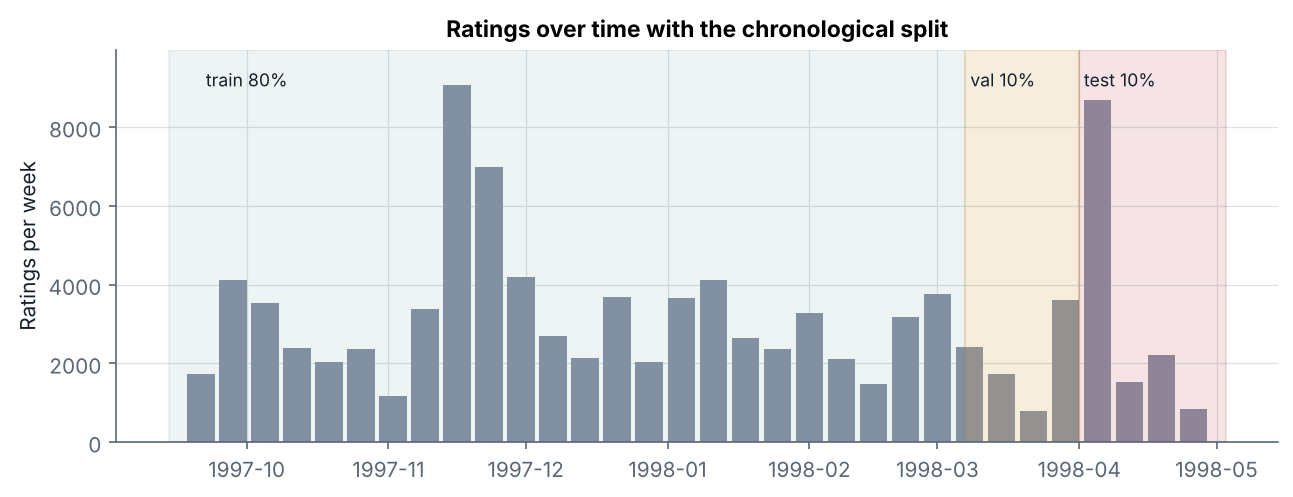

In [10]:
display(Image(str(C.FIG_DIR / 'eda_ratings_over_time.png')))

Ratings run from Sept 1997 to April 1998. Activity is bursty: many users rate dozens of movies in one session. This matters a lot for the experiment (see notebook 02).